Saving plasma_G1_1min_FINAL.csv to plasma_G1_1min_FINAL.csv

File uploaded:
plasma_G1_1min_FINAL.csv

DATASET STRUCTURE
Rows: 26077
Columns: 10

Columns:
- _id
- __v
- createdAt
- datetime
- doorStatus
- dsTemperature
- humidity
- time_slot
- username
- interval_min

VALIDATION
Invalid datetime: 0
Invalid temperature: 0
Duplicate timestamps: 0

TEMPORAL COVERAGE
N observations: 26077
Start: 2026-08-21 17:43:38+00:00
End: 2026-09-08 21:40:00+00:00
Duration: 435.9394 hours
Duration: 18.1641 days
Median sampling interval: 1.0 min
Mean sampling interval: 1.0031 min

MISSING-DATA CHARACTERIZATION
Gap threshold: 1.5 min
Number of gaps: 13
Estimated missing observations: 86
Expected observations: 26163
Estimated missing percentage: 0.3287 %
Maximum gap: 40.0167 min
Median gap: 2.0167 min

Largest gaps:
                 datetime  interval_min  estimated_missing
2026-08-21 18:40:01+00:00     40.016667                 39
2026-08-21 18:00:00+00:00     16.366667                 15
2026-08-21 18:50

/tmp/ipykernel_3084/3828719914.py:591: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
/tmp/ipykernel_3084/3828719914.py:656: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/tmp/ipykernel_3084/3828719914.py:656: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch 


ADF STATIONARITY TEST
ADF statistic: -1.888447
p-value: 0.3375153290843319
Lags used: 36
Observations: 7627
Critical values: {'1%': np.float64(-3.4312076769674644), '5%': np.float64(-2.8619190292148153), '10%': np.float64(-2.5669717527595175)}
Interpretation: fail to reject unit-root H0.

KPSS STATIONARITY TEST
KPSS statistic: 10.84788
p-value: 0.01
Lags used: 53
Critical values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
Interpretation: reject level-stationarity H0.

LINEAR DETRENDING
Original mean: -30.441506
Detrended mean: -0.0


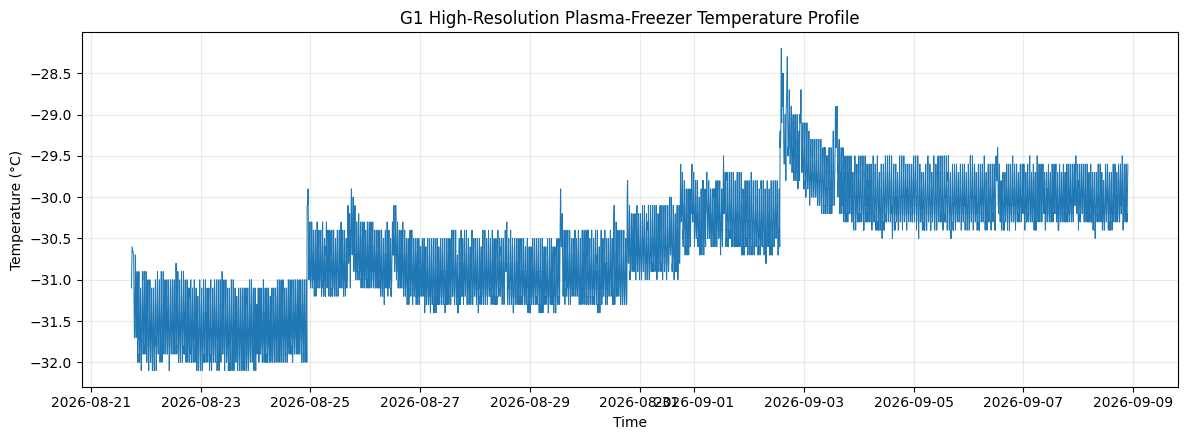

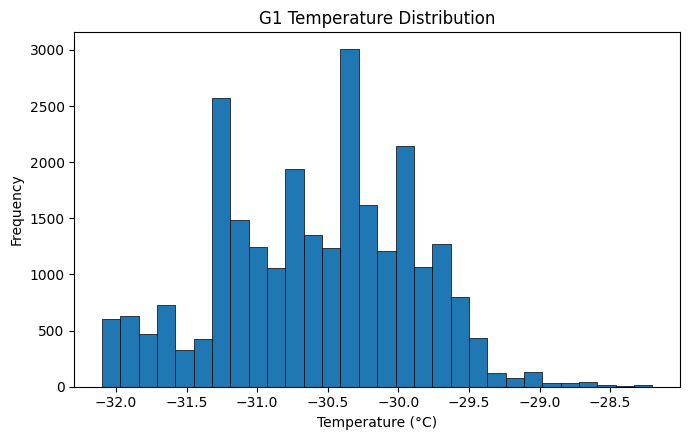


FILES GENERATED
- G1_analysis_summary.csv
- G1_descriptive_statistics.csv
- G1_short_term_variation.csv
- G1_gap_analysis.csv
- G1_statistical_tests.csv
- G1_longest_continuous_segment.csv
- G1_temperature_profile.png
- G1_temperature_histogram.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (8 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


G1 PART 1 COMPLETED


In [1]:
# ============================================================
# PAPER 02 - HRFEST 2026
# G1 ANALYSIS - PART 1
#
# Dataset:
# plasma_G1_1min_FINAL.csv
#
# Analysis:
# 1. Validation
# 2. Temporal coverage
# 3. Missing-data characterization
# 4. Descriptive statistics
# 5. Lilliefors normality test
# 6. Short-term temperature variation
# 7. ADF stationarity test
# 8. KPSS stationarity test
# 9. Linear detrending
#
# NO resampling is performed in this block.
# ============================================================

!pip -q install statsmodels

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.tsa.stattools import adfuller, kpss
from scipy.signal import detrend


# ============================================================
# 1. UPLOAD G1
# ============================================================

uploaded = files.upload()

filename = list(uploaded.keys())[0]

print("\nFile uploaded:")
print(filename)


# ============================================================
# 2. READ DATASET
# ============================================================

df = pd.read_csv(filename)

print("\n====================================================")
print("DATASET STRUCTURE")
print("====================================================")

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nColumns:")
for c in df.columns:
    print("-", c)


# ============================================================
# 3. BASIC CONVERSION
# ============================================================

datetime_col = "datetime"
temperature_col = "dsTemperature"

df[datetime_col] = pd.to_datetime(
    df[datetime_col],
    errors="coerce",
    utc=True
)

df[temperature_col] = pd.to_numeric(
    df[temperature_col],
    errors="coerce"
)

invalid_datetime = df[datetime_col].isna().sum()
invalid_temperature = df[temperature_col].isna().sum()

print("\n====================================================")
print("VALIDATION")
print("====================================================")

print("Invalid datetime:", invalid_datetime)
print("Invalid temperature:", invalid_temperature)


df = (
    df
    .dropna(subset=[datetime_col, temperature_col])
    .sort_values(datetime_col)
    .reset_index(drop=True)
)


# ============================================================
# 4. DUPLICATES
# ============================================================

duplicates = df.duplicated(
    subset=[datetime_col]
).sum()

print("Duplicate timestamps:", duplicates)


# ============================================================
# 5. TEMPORAL COVERAGE
# ============================================================

start = df[datetime_col].min()
end = df[datetime_col].max()

duration_h = (
    end - start
).total_seconds() / 3600

duration_days = duration_h / 24


df["interval_min"] = (
    df[datetime_col]
    .diff()
    .dt.total_seconds()
    / 60
)


print("\n====================================================")
print("TEMPORAL COVERAGE")
print("====================================================")

print("N observations:", len(df))
print("Start:", start)
print("End:", end)

print(
    "Duration:",
    round(duration_h, 4),
    "hours"
)

print(
    "Duration:",
    round(duration_days, 4),
    "days"
)

print(
    "Median sampling interval:",
    round(df["interval_min"].median(), 4),
    "min"
)

print(
    "Mean sampling interval:",
    round(df["interval_min"].mean(), 4),
    "min"
)


# ============================================================
# 6. MISSING-DATA / GAP ANALYSIS
# ============================================================

NOMINAL_INTERVAL = 1.0
GAP_THRESHOLD = 1.5

gaps = df[
    df["interval_min"] > GAP_THRESHOLD
].copy()

gaps["estimated_missing"] = np.maximum(
    np.round(
        gaps["interval_min"] / NOMINAL_INTERVAL
    ).astype(int) - 1,
    0
)

estimated_missing = int(
    gaps["estimated_missing"].sum()
)

expected_total = (
    len(df) + estimated_missing
)

missing_pct = (
    estimated_missing
    / expected_total
    * 100
)


print("\n====================================================")
print("MISSING-DATA CHARACTERIZATION")
print("====================================================")

print("Gap threshold:", GAP_THRESHOLD, "min")
print("Number of gaps:", len(gaps))

print(
    "Estimated missing observations:",
    estimated_missing
)

print(
    "Expected observations:",
    expected_total
)

print(
    "Estimated missing percentage:",
    round(missing_pct, 4),
    "%"
)


if len(gaps) > 0:

    print(
        "Maximum gap:",
        round(
            gaps["interval_min"].max(),
            4
        ),
        "min"
    )

    print(
        "Median gap:",
        round(
            gaps["interval_min"].median(),
            4
        ),
        "min"
    )

    print("\nLargest gaps:")

    print(
        gaps[
            [
                datetime_col,
                "interval_min",
                "estimated_missing"
            ]
        ]
        .sort_values(
            "interval_min",
            ascending=False
        )
        .head(20)
        .to_string(index=False)
    )


# ============================================================
# 7. DESCRIPTIVE STATISTICS
# ============================================================

temp = df[temperature_col]

descriptive = pd.DataFrame({
    "Statistic": [
        "N",
        "Mean",
        "Median",
        "Standard deviation",
        "Minimum",
        "Maximum",
        "Range",
        "Q1",
        "Q3",
        "IQR"
    ],

    "Value": [
        len(temp),
        temp.mean(),
        temp.median(),
        temp.std(ddof=1),
        temp.min(),
        temp.max(),
        temp.max() - temp.min(),
        temp.quantile(0.25),
        temp.quantile(0.75),
        temp.quantile(0.75)
        - temp.quantile(0.25)
    ]
})


print("\n====================================================")
print("DESCRIPTIVE STATISTICS")
print("====================================================")

print(
    descriptive.to_string(
        index=False
    )
)


# ============================================================
# 8. PERCENTILES
# ============================================================

percentiles = temp.quantile(
    [
        0.01,
        0.05,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)


print("\n====================================================")
print("TEMPERATURE PERCENTILES")
print("====================================================")

print(percentiles)


# ============================================================
# 9. LILLIEFORS NORMALITY TEST
# ============================================================
#
# H0: data follow a normal distribution.
#
# p < 0.05:
# reject normality.
# ============================================================

lillie_stat, lillie_p = lilliefors(
    temp.values,
    dist="norm"
)


print("\n====================================================")
print("LILLIEFORS NORMALITY TEST")
print("====================================================")

print(
    "Statistic:",
    round(lillie_stat, 6)
)

print(
    "p-value:",
    lillie_p
)

if lillie_p < 0.05:

    print(
        "Result: reject H0 -> "
        "temperature distribution is not normal."
    )

else:

    print(
        "Result: H0 is not rejected."
    )


# ============================================================
# 10. SHORT-TERM TEMPERATURE VARIATION
# ============================================================
#
# Consecutive differences are calculated only for intervals
# sufficiently close to the nominal 1-min sampling interval.
#
# This prevents large acquisition gaps from being interpreted
# as ordinary minute-to-minute changes.
# ============================================================

df["delta_temp"] = (
    df[temperature_col].diff()
)

valid_consecutive = (
    (df["interval_min"] >= 0.5)
    &
    (df["interval_min"] <= 1.5)
)

delta = (
    df.loc[
        valid_consecutive,
        "delta_temp"
    ]
    .dropna()
)

abs_delta = delta.abs()


print("\n====================================================")
print("SHORT-TERM TEMPERATURE VARIATION")
print("====================================================")

print(
    "Valid consecutive pairs:",
    len(delta)
)

print(
    "Mean signed change:",
    round(delta.mean(), 6),
    "°C"
)

print(
    "Mean absolute change:",
    round(abs_delta.mean(), 6),
    "°C"
)

print(
    "Median absolute change:",
    round(abs_delta.median(), 6),
    "°C"
)

print(
    "Maximum absolute change:",
    round(abs_delta.max(), 6),
    "°C"
)


thresholds = [
    0.1,
    0.2,
    0.3,
    0.5,
    1.0
]


short_term_results = []


for threshold in thresholds:

    percentage = (
        abs_delta <= threshold
    ).mean() * 100

    short_term_results.append({
        "Threshold_C":
            threshold,

        "Pairs_within_threshold_pct":
            percentage
    })


short_term_table = pd.DataFrame(
    short_term_results
)


print("\nPercentage of consecutive changes within thresholds:")

print(
    short_term_table
    .to_string(
        index=False
    )
)


# ============================================================
# 11. PREPARE REGULAR CONTINUOUS SERIES FOR TIME-SERIES TESTS
# ============================================================
#
# IMPORTANT:
#
# ADF/KPSS should not simply ignore temporal gaps.
#
# We identify continuous segments where consecutive
# observations remain within the expected ~1-min regime.
#
# The LONGEST continuous segment is used for the stationarity
# analysis.
# ============================================================

is_break = (
    (df["interval_min"].isna())
    |
    (df["interval_min"] < 0.5)
    |
    (df["interval_min"] > 1.5)
)

df["segment"] = is_break.cumsum()


segment_sizes = (
    df.groupby("segment")
    .size()
    .sort_values(
        ascending=False
    )
)


largest_segment_id = (
    segment_sizes.index[0]
)


continuous = (
    df[
        df["segment"]
        == largest_segment_id
    ]
    .copy()
    .reset_index(drop=True)
)


print("\n====================================================")
print("LONGEST CONTINUOUS ~1-MIN SEGMENT")
print("====================================================")

print(
    "N:",
    len(continuous)
)

print(
    "Start:",
    continuous[datetime_col].min()
)

print(
    "End:",
    continuous[datetime_col].max()
)

continuous_duration = (
    continuous[datetime_col].max()
    -
    continuous[datetime_col].min()
).total_seconds() / 3600


print(
    "Duration:",
    round(
        continuous_duration,
        4
    ),
    "hours"
)


# ============================================================
# 12. ADF TEST
# ============================================================
#
# H0 = unit root / non-stationary.
#
# p < 0.05:
# evidence against unit root.
# ============================================================

series = (
    continuous[temperature_col]
    .astype(float)
    .values
)


adf_result = adfuller(
    series,
    autolag="AIC"
)


adf_stat = adf_result[0]
adf_p = adf_result[1]
adf_lags = adf_result[2]
adf_nobs = adf_result[3]


print("\n====================================================")
print("ADF STATIONARITY TEST")
print("====================================================")

print(
    "ADF statistic:",
    round(adf_stat, 6)
)

print(
    "p-value:",
    adf_p
)

print(
    "Lags used:",
    adf_lags
)

print(
    "Observations:",
    adf_nobs
)

print(
    "Critical values:",
    adf_result[4]
)


if adf_p < 0.05:

    print(
        "Interpretation: reject unit-root H0."
    )

else:

    print(
        "Interpretation: fail to reject unit-root H0."
    )


# ============================================================
# 13. KPSS TEST
# ============================================================
#
# H0 = level stationary.
#
# p < 0.05:
# reject level stationarity.
# ============================================================

kpss_result = kpss(
    series,
    regression="c",
    nlags="auto"
)


kpss_stat = kpss_result[0]
kpss_p = kpss_result[1]
kpss_lags = kpss_result[2]


print("\n====================================================")
print("KPSS STATIONARITY TEST")
print("====================================================")

print(
    "KPSS statistic:",
    round(kpss_stat, 6)
)

print(
    "p-value:",
    kpss_p
)

print(
    "Lags used:",
    kpss_lags
)

print(
    "Critical values:",
    kpss_result[3]
)


if kpss_p < 0.05:

    print(
        "Interpretation: reject level-stationarity H0."
    )

else:

    print(
        "Interpretation: fail to reject "
        "level-stationarity H0."
    )


# ============================================================
# 14. LINEAR DETRENDING
# ============================================================

continuous["temperature_detrended"] = detrend(
    series,
    type="linear"
)


print("\n====================================================")
print("LINEAR DETRENDING")
print("====================================================")

print(
    "Original mean:",
    round(
        np.mean(series),
        6
    )
)

print(
    "Detrended mean:",
    round(
        continuous[
            "temperature_detrended"
        ].mean(),
        10
    )
)


# ============================================================
# 15. FIGURE - FULL G1 TEMPERATURE PROFILE
# ============================================================

plt.figure(
    figsize=(12, 4.5)
)

plt.plot(
    df[datetime_col],
    df[temperature_col],
    linewidth=0.7
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title(
    "G1 High-Resolution Plasma-Freezer Temperature Profile"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "G1_temperature_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 16. FIGURE - TEMPERATURE DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(7, 4.5)
)

plt.hist(
    temp,
    bins=30,
    edgecolor="black",
    linewidth=0.5
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.title(
    "G1 Temperature Distribution"
)

plt.tight_layout()

plt.savefig(
    "G1_temperature_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 17. EXPORT RESULTS
# ============================================================

descriptive.to_csv(
    "G1_descriptive_statistics.csv",
    index=False
)

short_term_table.to_csv(
    "G1_short_term_variation.csv",
    index=False
)

gaps.to_csv(
    "G1_gap_analysis.csv",
    index=False
)

continuous.to_csv(
    "G1_longest_continuous_segment.csv",
    index=False
)


test_results = pd.DataFrame({
    "Test": [
        "Lilliefors",
        "ADF",
        "KPSS"
    ],

    "Statistic": [
        lillie_stat,
        adf_stat,
        kpss_stat
    ],

    "p_value": [
        lillie_p,
        adf_p,
        kpss_p
    ]
})


test_results.to_csv(
    "G1_statistical_tests.csv",
    index=False
)


summary_results = pd.DataFrame({
    "Metric": [
        "N",
        "Duration_hours",
        "Duration_days",
        "Median_interval_min",
        "Number_of_gaps",
        "Estimated_missing",
        "Estimated_missing_pct",
        "Valid_consecutive_pairs",
        "Longest_continuous_segment_N",
        "Longest_continuous_segment_hours"
    ],

    "Value": [
        len(df),
        duration_h,
        duration_days,
        df["interval_min"].median(),
        len(gaps),
        estimated_missing,
        missing_pct,
        len(delta),
        len(continuous),
        continuous_duration
    ]
})


summary_results.to_csv(
    "G1_analysis_summary.csv",
    index=False
)


print("\n====================================================")
print("FILES GENERATED")
print("====================================================")

generated_files = [
    "G1_analysis_summary.csv",
    "G1_descriptive_statistics.csv",
    "G1_short_term_variation.csv",
    "G1_gap_analysis.csv",
    "G1_statistical_tests.csv",
    "G1_longest_continuous_segment.csv",
    "G1_temperature_profile.png",
    "G1_temperature_histogram.png"
]


for f in generated_files:
    print("-", f)


# ============================================================
# 18. DOWNLOAD RESULTS
# ============================================================

for f in generated_files:
    files.download(f)


print("\n====================================================")
print("G1 PART 1 COMPLETED")
print("====================================================")